# A2: can terrain explain the station-specific correction?

**Background (A1).**
* A separate ridge regression per station on the IFS and AIFS wind at that station lowers the
  vector RMSE of the mean of IFS and AIFS by 15–23 %.
* The operators with the target station included reach the same level. They can recognise the
  station from its position and learn its own correction.
* For a station not seen in training, every operator gives ≈ 0 %.

**Question.** Can the station-specific correction be predicted from descriptors that exist at
every 1 km cell, so that it also works where there is no station? The model is never told which
station it is or where it is. It is only told what the terrain and surface look like there.

**Test.** Always on station groups that were not used for training: the 5 spatially blocked
groups of A1, each predicted by a model fitted on the other 4. A method that only memorises
stations gains nothing here.

**Descriptors** (scripts/build_terrain_descriptors.py; 1 km grid of northern Norway, from the
Kartverket terrain model, nearest cell to the station):

| group | descriptors |
|---|---|
| elevation and height relative to the surroundings | elevation; elevation minus its 1 km and 5 km mean; elevation minus its Gaussian mean with σ 5 km and 12 km (the 12 km version ≈ height above the terrain a 0.25° model sees) |
| slope, aspect and roughness | slope; sin and cos of the downslope bearing; standard deviation of elevation within 1 km |
| land and coast | land fraction of the cell; land fraction averaged with σ 5 km and 12 km (open sea, fjord, inland) |
| shelter within 1 km | for 8 directions, the steepest terrain rise within 1 km toward that direction (angle; positive = sheltered from wind blowing from there) |
| shelter within 10 km | the same within 10 km |
| upwind shelter | the shelter angle (1 km and 10 km) toward the direction the model wind blows from, interpolated between the 8 sectors; changes with every forecast |

Same data, split and test samples as A1 (test 2025-04-01 – 2025-09-12). Metric: vector RMSE of
(u, v); change in % against the mean of IFS and AIFS, negative = better.


In [1]:
import sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, '..')
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.ensemble import HistGradientBoostingRegressor
from windcast.station_correction import station_groups
from windcast.station_correction import upwind, SX_DIRS
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
ROOT = Path('/cluster/work/projects/nn8106k/siyan/windcast')
d = dict(np.load(ROOT / 'cache/multimodel_2024-03-01_2025-09-12.npz', allow_pickle=True))
inits, leads = pd.DatetimeIndex(d['inits']), d['leads']
fc = d['st_fc'].astype(float)                       # (N, L, M, S, 2)
N, L, M, S, _ = fc.shape
tindex = pd.Index(d['time']); ti = tindex.get_indexer(inits)
obs = d['obs'].astype(float)
o_valid = np.stack([obs[ti + ld] for ld in leads], 1)
base = fc.mean(2)
y = o_valid - base
prev = pd.Index(inits).get_indexer(inits - pd.Timedelta(hours=12))
omf = np.full((N, M, S, 2), np.nan)
ok = prev >= 0
omf[ok] = obs[ti[ok]][:, None] - fc[prev[ok], list(leads).index(12)]
groups = station_groups(d['xy'].astype(float))
def span(a, b): return np.asarray((inits >= a) & (inits <= pd.Timestamp(b) + pd.Timedelta(hours=12)) & d['keep'])
tr, va, te = span('2024-03-01', '2024-12-31'), span('2025-01-01', '2025-03-31'), span('2025-04-01', '2025-09-12')
own_ok = np.isfinite(omf).all((1, 3))
base_mask = own_ok & (own_ok.sum(1)[:, None] - 1 >= 3)
TEST = base_mask[:, None, :] & np.isfinite(y[..., 0]) & te[:, None, None]     # same samples as A1
TRAIN = np.isfinite(y[..., 0]) & np.isfinite(base[..., 0]) & tr[:, None, None]

T = np.load(ROOT / 'cache/station_terrain.npz', allow_pickle=True)
assert (T['station'] == d['station']).all()
tn = [str(x) for x in T['names']]
Dst = T['values'].astype(float)                     # (S, 28)
u, v = base[..., 0], base[..., 1]
spd = np.hypot(u, v)
frm = np.arctan2(-u, -v) % (2 * np.pi)              # bearing the model wind blows from
up1 = upwind(Dst[:, [tn.index(f'sx_{k}') for k in SX_DIRS]], u, v)
up10 = upwind(Dst[:, [tn.index(f'sx10_{k}') for k in SX_DIRS]], u, v)
print(f'{S} stations, {len(tn)} descriptors; train runs {tr.sum()}, test runs {te.sum()}; group sizes', np.bincount(groups))
P, NAMES = {}, {}
P['Mean of IFS and AIFS'] = np.zeros_like(y)
def rmse_table(P, mask=TEST):
    rows = {}
    for k, p in P.items():
        rows[k] = [np.sqrt(((y[:, j][mask[:, j]] - p[:, j][mask[:, j]]) ** 2).sum(-1).mean()) for j in range(L)]
    R = pd.DataFrame(rows, index=pd.Index(leads, name='lead (h)')).T
    return R, (R / R.loc['Mean of IFS and AIFS'] - 1) * 100

99 stations, 28 descriptors; train runs 592, test runs 330; group sizes [28 17 14 20 20]


## 1. The station-specific correction as six numbers per station

As a compact version of the station-wise ridge regression of A1, fit for every station one
linear correction of the mean wind, pooled over all leads:

    y = A · (u, v)_base + b        A: 2 × 2,  b: 2   (6 coefficients)

A contains the speed factor (its mean diagonal) and the turning of the wind direction (its
antisymmetric part); b is a constant offset. It is fitted on the training period of each station.
If this keeps most of the A1 gain, these six numbers per station are what terrain would have to
predict.

In [2]:
COEF = ['A_uu', 'A_uv', 'A_vu', 'A_vv', 'b_u', 'b_v']
coef = np.zeros((S, 6))
P['Station-wise linear correction of the mean wind (needs the station history)'] = pst = np.zeros_like(y)
for s in range(S):
    m = TRAIN[:, :, s]
    X = np.stack([u[:, :, s][m], v[:, :, s][m]], -1)
    for c in range(2):
        r = Ridge(alpha=1.0).fit(X, y[:, :, s, c][m])
        coef[s, 2 * c:2 * c + 2], coef[s, 4 + c] = r.coef_, r.intercept_
    pst[:, :, s] = np.einsum('ck,nlk->nlc', coef[s, :4].reshape(2, 2), base[:, :, s]) + coef[s, 4:]
def apply(cf):                                     # (S, 6) -> correction (N, L, S, 2)
    A = cf[:, :4].reshape(S, 2, 2)
    return np.einsum('sck,nlsk->nlsc', A, base) + cf[None, None, :, 4:]
cdf = pd.DataFrame(coef, columns=COEF)
cdf['speed factor'] = 1 + (cdf.A_uu + cdf.A_vv) / 2
cdf['turning (deg, + = clockwise)'] = np.degrees((cdf.A_vu - cdf.A_uv) / 2) * -1
display(cdf[['speed factor', 'turning (deg, + = clockwise)', 'b_u', 'b_v']].describe().round(2))
R, chg = rmse_table(P)
display(chg.round(1))
a1 = pd.read_csv(ROOT / 'results/a1/rmse_change_pct.csv', index_col=0)
a1.columns = leads
print('A1, station-wise ridge regression on IFS and AIFS wind (per lead, both models):')
display(a1.loc[['Station-wise ridge regression on IFS and AIFS wind']].round(1))

,speed factor,"turning (deg, + = clockwise)",b_u,b_v
count,99.00,99.00,99.00,99.00
mean,1.12,-2.87,0.16,0.03
std,0.57,16.15,0.51,0.53
min,0.03,-27.71,-1.09,-1.08
25%,0.76,-10.76,-0.11,-0.29
50%,1.00,-6.20,0.11,-0.02
75%,1.31,2.08,0.40,0.22
max,3.63,88.52,2.92,2.35


lead (h),0,6,12,18,24,30,36,42,48,54,60,66
Mean of IFS and AIFS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Station-wise linear correction of the mean wind (needs the station history),-19.6,-22.2,-20.8,-21.0,-19.5,-19.8,-18.2,-18.2,-16.6,-16.6,-15.4,-14.7


A1, station-wise ridge regression on IFS and AIFS wind (per lead, both models):


,0,6,12,18,24,30,36,42,48,54,60,66
Station-wise ridge regression on IFS and AIFS wind,-21.6,-22.8,-21.2,-21.0,-19.9,-19.7,-18.3,-18.1,-16.7,-16.5,-15.3,-14.6


## 2. Predicting the six numbers from terrain (station groups held out)

For each held-out group, a regression from the 28 standardised descriptors of a station to its six
coefficients is fitted on the stations of the other four groups. The predicted coefficients are
then applied to the held-out stations' forecasts.

* **Ridge regression** (regularisation chosen by cross-validation on the training stations).
* **Gaussian process** with one length scale per descriptor (squared-exponential kernel + noise),
  hyperparameters by maximum marginal likelihood.
* Reference: **the same correction for all stations** (the mean coefficients of the training
  stations).

Skill of the coefficient prediction: R² = 1 − Σ(predicted − true)² / Σ(training mean − true)²,
over the held-out stations. R² > 0 means terrain predicts the station's coefficients better than
the training-station mean.

/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sk

/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sk

/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sk

/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sk

/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 8 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sk

/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 9 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sk

... (22 outputs left out)

/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sk

R² of the coefficients on held-out station groups (0 = no better than the training-station mean)


/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 9 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 11 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/tmp/wc-venv-3010425/lib/python3.11/site-packages/s

,A_uu,A_uv,A_vu,A_vv,b_u,b_v
Ridge regression,0.44,0.23,0.03,0.28,0.20,0.01
Gaussian process,0.02,0.09,-0.26,-0.11,-0.11,0.25


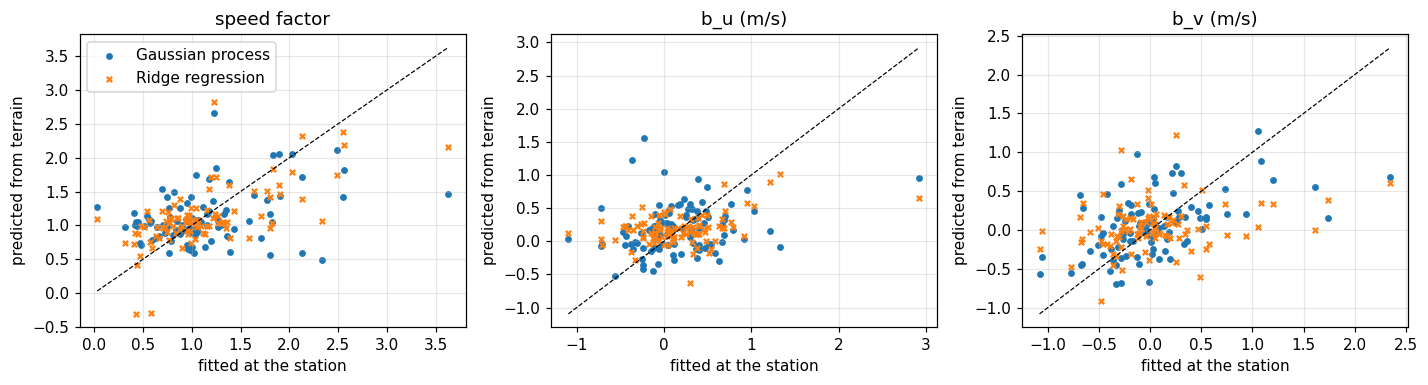

In [3]:
Z = StandardScaler().fit_transform(Dst)
pred_c = {k: np.zeros((S, 6)) for k in ['same', 'ridge', 'gp']}
for k in range(5):
    a_, b_ = groups != k, groups == k
    mu = coef[a_].mean(0)
    pred_c['same'][b_] = mu
    pred_c['ridge'][b_] = RidgeCV(alphas=np.logspace(-1, 3, 20)).fit(Z[a_], coef[a_]).predict(Z[b_])
    for c in range(6):
        kern = ConstantKernel(1.0) * RBF(length_scale=np.full(Z.shape[1], 3.0), length_scale_bounds=(0.3, 1e3)) + WhiteKernel(0.5)
        gp = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=2, random_state=0).fit(Z[a_], coef[a_, c])
        pred_c['gp'][b_, c] = gp.predict(Z[b_])
r2 = pd.DataFrame({m: 1 - ((pred_c[m] - coef) ** 2).sum(0) / ((pred_c['same'] - coef) ** 2).sum(0)
                   for m in ['ridge', 'gp']}, index=COEF).T
r2.index = ['Ridge regression', 'Gaussian process']
print('R² of the coefficients on held-out station groups (0 = no better than the training-station mean)')
display(r2.round(2))
NAMES = {'same': 'Same linear correction for all stations',
         'ridge': 'Linear correction, coefficients from terrain by ridge regression',
         'gp': 'Linear correction, coefficients from terrain by Gaussian process'}
for m, nm in NAMES.items():
    P[nm] = apply(pred_c[m])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
sf = lambda cf: 1 + (cf[:, 0] + cf[:, 3]) / 2
for a, (lab, f) in zip(ax, [('speed factor', sf), ('b_u (m/s)', lambda cf: cf[:, 4]), ('b_v (m/s)', lambda cf: cf[:, 5])]):
    a.scatter(f(coef), f(pred_c['gp']), s=12, label='Gaussian process')
    a.scatter(f(coef), f(pred_c['ridge']), s=12, marker='x', label='Ridge regression')
    lo, hi = f(coef).min(), f(coef).max(); a.plot([lo, hi], [lo, hi], 'k--', lw=.8)
    a.set_xlabel('fitted at the station'); a.set_ylabel('predicted from terrain'); a.set_title(lab)
ax[0].legend(); plt.tight_layout()

## 3. Learning the correction directly from model wind, time and terrain

Instead of going through six coefficients per station, fit one model on all samples of the
training stations and predict the held-out stations:

* **Ridge regression with terrain × wind**: features (u, v, 1) of the mean wind, each multiplied
  by (1, 28 descriptors, upwind shelter within 1 km and 10 km): 93 features; the
  coefficients A and b become linear functions of terrain.
* **Gradient boosting on model wind and time**: IFS u, v; AIFS u, v; speed and direction of the
  mean wind; lead; hour and day of year (sin, cos). No terrain: one correction for all stations,
  but nonlinear in the wind.
* **Gradient boosting on model wind, time and terrain**: the same plus the 28 descriptors and the
  two upwind shelter angles.

* **Gradient boosting on model wind, time and other stations' obs-forecast**, and the same
  **with terrain**: adds the inverse-distance-weighted mean (weights 1 / (d² + (10 km)²)) of
  the obs-forecast at init time of the reporting stations outside the held-out group. A station never takes these inputs
  from its own spatial group, so training stations see neighbours as far away as the held-out
  stations do. The weight sum (how close the stations are) is deliberately not a feature:
  it is nearly constant for a station, so it identifies training stations. With it, gradient
  boosting memorised them and was 5–7 % worse than no correction on held-out stations; without
  it, about 0 %. This feature also exists at any point.

Gradient boosting: scikit-learn histogram gradient boosting, 300 trees, learning rate 0.05,
at least 500 samples per leaf (so a leaf cannot single out one station's few hundred samples
easily), one model per component u, v and held-out group.

In [4]:
hour = np.array([(inits + pd.Timedelta(hours=int(l))).hour for l in leads]).T
doy = np.array([(inits + pd.Timedelta(hours=int(l))).dayofyear for l in leads]).T
bc = lambda a: np.broadcast_to(a, (N, L, S))
WT = np.stack([fc[:, :, 0, :, 0], fc[:, :, 0, :, 1], fc[:, :, 1, :, 0], fc[:, :, 1, :, 1], spd, np.sin(frm), np.cos(frm),
               bc((leads / 66.0)[None, :, None]), bc(np.sin(2 * np.pi * hour / 24)[..., None]), bc(np.cos(2 * np.pi * hour / 24)[..., None]),
               bc(np.sin(2 * np.pi * doy / 366)[..., None]), bc(np.cos(2 * np.pi * doy / 366)[..., None])], -1).astype(np.float32)
TER = np.concatenate([np.broadcast_to(Z[None, None], (N, L, S, Z.shape[1])), up1[..., None], up10[..., None]], -1).astype(np.float32)
TER_NAMES = tn + ['upwind shelter 1 km', 'upwind shelter 10 km']
TER[..., -2:] = (TER[..., -2:] - np.nanmean(TER[..., -2:][TRAIN], 0)) / np.nanstd(TER[..., -2:][TRAIN], 0)
def interactions(m):
    t = np.concatenate([np.ones((m.sum(), 1), np.float32), TER[m]], 1)
    w = np.stack([u[m], v[m], np.ones(m.sum())], 1).astype(np.float32)
    return (w[:, :, None] * t[:, None, :]).reshape(m.sum(), -1)
HGB = dict(max_iter=300, learning_rate=0.05, min_samples_leaf=500, l2_regularization=1.0, random_state=0)
GB_OBS = "Gradient boosting on model wind, time and other stations' obs-forecast"
GB_ALL = "Gradient boosting on model wind, time, terrain and other stations' obs-forecast"
d0 = omf.mean(1); a0 = np.isfinite(d0[..., 0])
xy_ = d['xy'].astype(float); Wd = 1.0 / (((xy_[:, None] - xy_[None]) ** 2).sum(-1) + 100.0)
def idw_fold(k):
    # inputs never come from the held-out group, nor from the station's own group: a training station
    # then sees neighbours as far away as a held-out station does
    Wk = Wd * (groups != k)[None, :] * (groups[None, :] != groups[:, None])
    num = np.einsum('sr,nrc->nsc', Wk, np.nan_to_num(d0) * a0[..., None]); den = np.einsum('sr,nr->ns', Wk, a0)
    f = num / np.maximum(den, 1e-12)[..., None]
    return np.broadcast_to(f[:, None], (N, L, S, 2)).astype(np.float32)
for nm in ['Ridge regression with terrain × wind', 'Gradient boosting on model wind and time',
           'Gradient boosting on model wind, time and terrain', GB_OBS, GB_ALL]:
    P[nm] = np.full_like(y, np.nan)
MODELS = {}
EVAL = np.isfinite(base[..., 0])
import time; t0 = time.time()
for k in range(5):
    mt = TRAIN & (groups != k)[None, None]
    me = EVAL & (groups == k)[None, None]
    Xi_t, Xi_e = interactions(mt), interactions(me)
    OB = idw_fold(k)
    sc = StandardScaler().fit(Xi_t)
    for c in range(2):
        P['Ridge regression with terrain × wind'][..., c][me] = Ridge(alpha=10.0).fit(sc.transform(Xi_t), y[..., c][mt]).predict(sc.transform(Xi_e))
        for nm, X in [('Gradient boosting on model wind and time', WT),
                      ('Gradient boosting on model wind, time and terrain', np.concatenate([WT, TER], -1)),
                      (GB_OBS, np.concatenate([WT, OB], -1)), (GB_ALL, np.concatenate([WT, TER, OB], -1))]:
            g = HistGradientBoostingRegressor(**HGB).fit(X[mt], y[..., c][mt])
            P[nm][..., c][me] = g.predict(X[me])
            MODELS[(nm, k, c)] = g
    print(f'group {k} done ({time.time() - t0:.0f} s)', flush=True)

group 0 done (18 s)


group 1 done (36 s)


group 2 done (55 s)


group 3 done (73 s)


group 4 done (91 s)


## 4. Results on held-out station groups (test, 2025-04 – 09)

vector RMSE (m/s)


lead (h),0,6,12,18,24,30,36,42,48,54,60,66
Mean of IFS and AIFS,3.36,3.36,3.40,3.42,3.45,3.45,3.49,3.51,3.56,3.58,3.62,3.67
Station-wise linear correction of the mean wind (needs the station history),2.70,2.61,2.69,2.70,2.78,2.77,2.85,2.87,2.97,2.98,3.07,3.13
Same linear correction for all stations,3.42,3.39,3.43,3.45,3.48,3.48,3.52,3.54,3.59,3.61,3.66,3.71
"Linear correction, coefficients from terrain by ridge regression",3.22,3.18,3.23,3.25,3.29,3.29,3.33,3.36,3.42,3.44,3.49,3.55
"Linear correction, coefficients from terrain by Gaussian process",3.49,3.42,3.48,3.48,3.52,3.51,3.56,3.56,3.63,3.63,3.69,3.73
Ridge regression with terrain × wind,3.49,3.40,3.47,3.45,3.51,3.49,3.55,3.55,3.63,3.63,3.69,3.73
Gradient boosting on model wind and time,3.38,3.37,3.42,3.44,3.47,3.47,3.50,3.53,3.58,3.60,3.64,3.68
"Gradient boosting on model wind, time and terrain",3.21,3.20,3.24,3.27,3.29,3.31,3.33,3.37,3.41,3.45,3.48,3.55
"Gradient boosting on model wind, time and other stations' obs-forecast",3.39,3.38,3.42,3.44,3.47,3.47,3.50,3.53,3.58,3.59,3.63,3.68
"Gradient boosting on model wind, time, terrain and other stations' obs-forecast",3.21,3.20,3.23,3.26,3.29,3.31,3.33,3.37,3.41,3.45,3.48,3.55


change vs Mean of IFS and AIFS (%), negative = better; all rows except the last are held-out stations


lead (h),0,6,12,18,24,30,36,42,48,54,60,66
Mean of IFS and AIFS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Same linear correction for all stations,1.8,1.0,0.9,1.0,0.9,0.9,0.9,1.0,0.9,1.0,1.0,1.3
"Linear correction, coefficients from terrain by ridge regression",-4.1,-5.3,-4.9,-4.9,-4.7,-4.7,-4.5,-4.3,-4.1,-3.8,-3.7,-3.1
"Linear correction, coefficients from terrain by Gaussian process",4.1,2.0,2.4,1.8,2.1,1.7,2.1,1.7,1.9,1.6,1.9,1.7
Ridge regression with terrain × wind,3.9,1.2,2.0,1.1,1.9,1.2,1.9,1.3,1.8,1.4,1.8,1.7
Gradient boosting on model wind and time,0.7,0.5,0.5,0.6,0.5,0.7,0.5,0.6,0.4,0.6,0.4,0.5
"Gradient boosting on model wind, time and terrain",-4.5,-4.5,-4.9,-4.4,-4.7,-4.1,-4.5,-3.8,-4.3,-3.6,-4.0,-3.2
"Gradient boosting on model wind, time and other stations' obs-forecast",0.9,0.6,0.5,0.6,0.5,0.7,0.5,0.7,0.4,0.5,0.3,0.4
"Gradient boosting on model wind, time, terrain and other stations' obs-forecast",-4.5,-4.6,-5.0,-4.4,-4.8,-4.1,-4.5,-3.8,-4.3,-3.6,-4.0,-3.3
"A1: Gaussian process with elevation, weighted stations excluding target",-6.6,-4.5,-2.6,-1.6,-1.2,-0.6,-0.7,-0.6,-0.7,-0.5,-0.5,-0.5


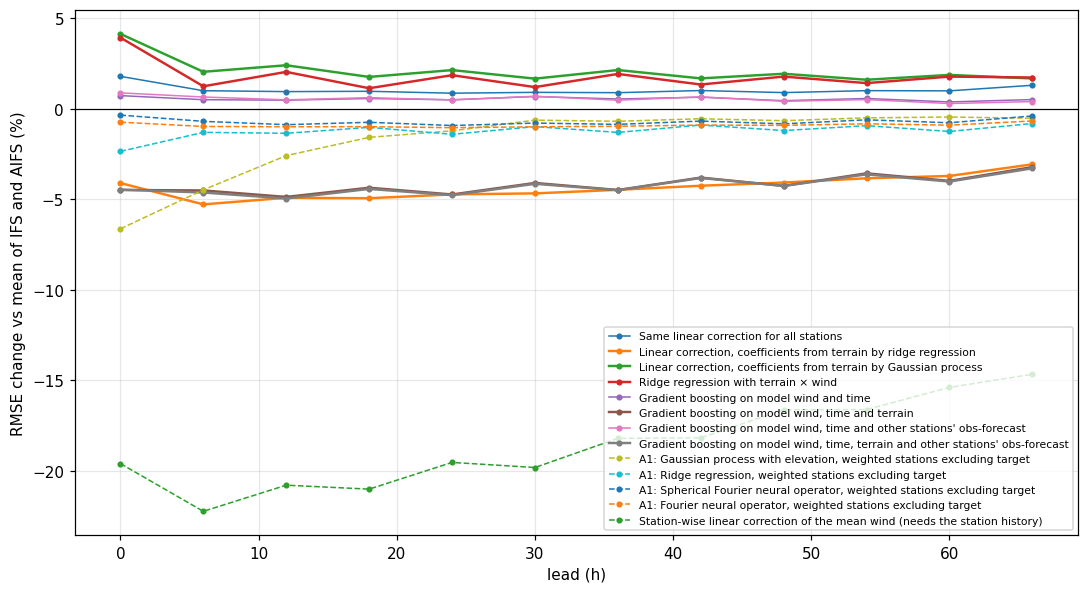

In [5]:
R, chg = rmse_table(P)
for name in ['Gaussian process with elevation, weighted stations excluding target',
             'Ridge regression, weighted stations excluding target',
             'Spherical Fourier neural operator, weighted stations excluding target',
             'Fourier neural operator, weighted stations excluding target']:
    chg.loc['A1: ' + name] = a1.loc[name].values
order = ['Mean of IFS and AIFS', 'Same linear correction for all stations',
         'Linear correction, coefficients from terrain by ridge regression',
         'Linear correction, coefficients from terrain by Gaussian process',
         'Ridge regression with terrain × wind', 'Gradient boosting on model wind and time',
         'Gradient boosting on model wind, time and terrain', GB_OBS, GB_ALL] + [i for i in chg.index if i.startswith('A1: ')] + \
        ['Station-wise linear correction of the mean wind (needs the station history)']
print('vector RMSE (m/s)'); display(R.round(2))
print('change vs Mean of IFS and AIFS (%), negative = better; all rows except the last are held-out stations')
CHG = chg.loc[order]; display(CHG.round(1))
fig, ax = plt.subplots(figsize=(10, 5.5))
for nm in order[1:]:
    ax.plot(leads, CHG.loc[nm], marker='o', ms=3, lw=1.6 if 'terrain' in nm else 1, ls='--' if nm.startswith('A1') or 'history' in nm else '-', label=nm)
ax.axhline(0, color='k', lw=.8); ax.set_xlabel('lead (h)'); ax.set_ylabel('RMSE change vs mean of IFS and AIFS (%)')
ax.legend(fontsize=7, loc='lower right'); plt.tight_layout()

### Where does terrain help?

Per held-out station: RMSE change of gradient boosting with terrain against the same model without
terrain, all leads pooled.

stations improved by terrain: 69 of 99
fraction of the station-wise gain recovered, per station (median): 0.23


/tmp/ipykernel_1643915/1980424488.py:3: RuntimeWarning: Mean of empty slice
  return np.array([np.sqrt(e[:, :, s][m[:, :, s]].mean()) for s in range(S)])
/tmp/wc-venv-3010425/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,station,group,elevation,land_30km,speed factor (station fit),terrain vs no terrain (%),station-wise fit vs mean (%),terrain model vs mean (%)
82,SN96890,3,385.78,0.99,1.77,-24.92,-36.04,-25.60
49,SN90491,4,729.66,0.67,2.57,-23.04,-33.67,-23.85
26,SN93611,2,549.25,1.00,1.90,-21.78,-32.86,-21.16
8,SN77280,0,59.77,1.00,0.41,-20.70,-26.79,-14.84
27,SN84630,1,825.61,0.79,3.63,-17.43,-32.70,-18.33
12,SN91530,4,1084.49,0.87,1.23,-17.33,-8.68,-16.54
90,SN88450,1,61.31,0.49,0.32,-16.89,-48.34,-16.60
37,SN93000,2,330.84,0.45,1.39,-16.63,-21.70,-14.53
58,SN99600,3,288.74,0.97,1.80,-16.41,-29.15,-14.53
86,SN79610,0,63.52,0.98,0.44,-14.88,-14.49,-8.79


,station,group,elevation,land_30km,speed factor (station fit),terrain vs no terrain (%),station-wise fit vs mean (%),terrain model vs mean (%)
28,SN98976,3,261.72,0.96,1.43,7.23,-9.15,7.65
31,SN80102,0,2.27,0.18,0.94,7.73,-11.96,-2.17
59,SN87120,1,288.42,0.24,1.18,7.79,-5.98,8.15
87,SN80705,0,677.57,0.83,1.04,10.02,-5.05,14.94
6,SN85890,0,1.72,0.01,0.94,11.05,-9.78,5.71
92,SN98400,3,23.81,0.34,0.98,11.54,-4.31,17.46
53,SN82410,0,5.85,0.04,1.01,15.09,-20.16,5.11
91,SN96220,3,103.23,0.59,0.76,18.64,-10.53,23.73
69,SN84880,1,450.29,0.96,0.88,30.85,-5.78,35.17
33,SN77150,0,581.13,0.92,2.49,NaN,NaN,NaN


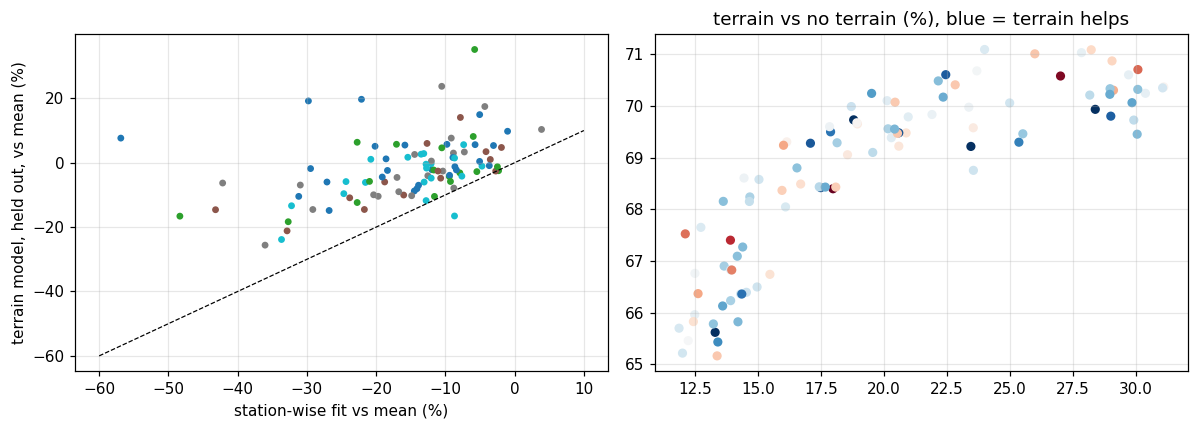

In [6]:
def st_rmse(p):
    e = ((y - p) ** 2).sum(-1); m = TEST
    return np.array([np.sqrt(e[:, :, s][m[:, :, s]].mean()) for s in range(S)])
r0 = st_rmse(P['Gradient boosting on model wind and time']); r1 = st_rmse(P['Gradient boosting on model wind, time and terrain'])
rs = st_rmse(P['Station-wise linear correction of the mean wind (needs the station history)']); rb = st_rmse(P['Mean of IFS and AIFS'])
sdf = pd.DataFrame({'station': d['station'], 'group': groups, 'elevation': Dst[:, tn.index('elevation')],
                    'land_30km': Dst[:, tn.index('land_30km')], 'speed factor (station fit)': cdf['speed factor'],
                    'terrain vs no terrain (%)': (r1 / r0 - 1) * 100, 'station-wise fit vs mean (%)': (rs / rb - 1) * 100,
                    'terrain model vs mean (%)': (r1 / rb - 1) * 100})
print(f"stations improved by terrain: {(sdf['terrain vs no terrain (%)'] < 0).sum()} of {S}")
print('fraction of the station-wise gain recovered, per station (median):',
      np.nanmedian(np.clip((rb - r1) / np.maximum(rb - rs, 1e-6), -2, 2)).round(2))
display(sdf.sort_values('terrain vs no terrain (%)').round(2).head(10)); display(sdf.sort_values('terrain vs no terrain (%)').round(2).tail(10))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(sdf['station-wise fit vs mean (%)'], sdf['terrain model vs mean (%)'], s=12, c=groups, cmap='tab10')
ax[0].plot([-60, 10], [-60, 10], 'k--', lw=.8); ax[0].set_xlabel('station-wise fit vs mean (%)'); ax[0].set_ylabel('terrain model, held out, vs mean (%)')
ax[1].scatter(d['lon_st'], d['lat_st'], c=sdf['terrain vs no terrain (%)'], cmap='RdBu_r', vmin=-20, vmax=20, s=25)
ax[1].set_title('terrain vs no terrain (%), blue = terrain helps'); plt.tight_layout()

## 5. Which descriptors matter

Permutation importance for gradient boosting with terrain: the descriptors of one group are
shuffled **between stations** (every station gets another station's terrain, the same for all
its samples), and the increase of the held-out vector RMSE is recorded (test, all leads, 3
shuffles).

In [7]:
GRP = {'elevation and relative height': ['elevation', 'tpi_1km', 'tpi_5km', 'elev_rel_10km', 'elev_rel_30km'],
       'slope, aspect, roughness': ['slope', 'aspect_sin', 'aspect_cos', 'std_1km'],
       'land and coast': ['land_fraction', 'land_10km', 'land_30km'],
       'shelter within 1 km (8 directions + upwind)': [f'sx_{k}' for k in SX_DIRS] + ['upwind shelter 1 km'],
       'shelter within 10 km (8 directions + upwind)': [f'sx10_{k}' for k in SX_DIRS] + ['upwind shelter 10 km']}
nm = 'Gradient boosting on model wind, time and terrain'
nwt = WT.shape[-1]
def predict_all(TERp):
    out = np.full_like(y, np.nan)
    for k in range(5):
        me = TEST & (groups == k)[None, None]
        X = np.concatenate([WT[me], TERp[me]], -1)
        for c in range(2):
            out[..., c][me] = MODELS[(nm, k, c)].predict(X)
    return out
def total(p): e = ((y - p) ** 2).sum(-1)[TEST]; return np.sqrt(e.mean())
ref = total(P[nm]); rng = np.random.default_rng(0); imp = {}
for gname, cols in GRP.items():
    ci = [TER_NAMES.index(c) for c in cols]; vals = []
    for rep in range(3):
        perm = rng.permutation(S); TERp = TER.copy()
        # static descriptors: another station's values; upwind shelter: recomputed from that station's sectors
        TERp[..., ci] = TER[:, :, perm][..., ci]
        vals.append((total(predict_all(TERp)) / ref - 1) * 100)
    imp[gname] = (np.mean(vals), np.std(vals))
imp = pd.DataFrame(imp, index=['RMSE increase (%)', 'sd over shuffles']).T.sort_values('RMSE increase (%)', ascending=False)
display(imp.round(2))

,RMSE increase (%),sd over shuffles
shelter within 10 km (8 directions + upwind),4.29,0.33
elevation and relative height,2.93,0.75
shelter within 1 km (8 directions + upwind),1.70,0.36
land and coast,0.28,0.07
"slope, aspect, roughness",0.02,0.09


## 6. Neural operators with terrain inputs (no coordinates)

`windcast.training.train_station_operator --inputs terrain` (no observations) and `--inputs both`
(terrain + the other stations' obs-forecast at init time). In "both", the obs-forecast is
rasterised onto the operator grid as in A1. For the point-wise network it is also
inverse-distance weighted to the point. Each training sample hides a random 25 % of the
stations from the input and scores only those, as in A1 "excluding target".


In [8]:
RUNS = ROOT / 'runs_a1'
TOPS = {'point': 'Point-wise network on model wind, time and terrain (no operator)',
        'fno': 'Fourier neural operator + point-wise terrain network',
        'sfno': 'Spherical Fourier neural operator + point-wise terrain network'}
TOPS_OBS = {'point': "Point-wise network on model wind, time, terrain and other stations' obs-forecast (no operator)",
            'sfno': "Spherical Fourier neural operator + point-wise terrain network, with other stations' obs-forecast"}
P2 = {'Mean of IFS and AIFS': P['Mean of IFS and AIFS']}
info = []
for (op, tag), nm_ in [((op, 'terrain'), v) for op, v in TOPS.items()] + [((op, 'terrainobs'), v) for op, v in TOPS_OBS.items()]:
    parts = [RUNS / f'{op}_{tag}_g{k}_s0' / 'pred.npz' for k in range(5)]
    if not all(p.exists() for p in parts):
        print('not finished:', nm_); continue
    acc = np.full_like(y, np.nan)
    for k, p in enumerate(parts):
        pk = np.load(p); assert (pk['groups'] == groups).all()
        acc[:, :, groups == k] = pk['test'][:, :, groups == k]
    P2[nm_] = acc
    h = [json.loads((p.parent / 'history.json').read_text()) for p in parts]
    info.append((nm_, h[0]['n_params'], len(h[0]['history']), np.mean([x['history'][-1]['sec'] for x in h])))
display(pd.DataFrame(info, columns=['method', 'parameters', 'epochs', 's per epoch']))
for k_ in ['Gradient boosting on model wind and time', 'Gradient boosting on model wind, time and terrain', GB_OBS, GB_ALL]:
    P2[k_] = P[k_]
R2, chg2 = rmse_table(P2)
for name in ['Gaussian process with elevation, weighted stations excluding target', 'Fourier neural operator, weighted stations excluding target']:
    chg2.loc['A1: ' + name] = a1.loc[name].values
print('change vs Mean of IFS and AIFS (%), held-out stations, negative = better'); display(chg2.round(1))

,method,parameters,epochs,s per epoch
0,"Point-wise network on model wind, time and ter...",22018,40,1.595517
1,Fourier neural operator + point-wise terrain n...,4538594,40,6.523590
2,Spherical Fourier neural operator + point-wise...,606434,40,8.586657
3,"Point-wise network on model wind, time, terrai...",22530,40,1.932241
4,Spherical Fourier neural operator + point-wise...,607586,40,9.780257


change vs Mean of IFS and AIFS (%), held-out stations, negative = better


lead (h),0,6,12,18,24,30,36,42,48,54,60,66
Mean of IFS and AIFS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"Point-wise network on model wind, time and terrain (no operator)",-4.1,-4.2,-4.4,-4.0,-4.2,-3.7,-3.8,-3.2,-3.3,-2.8,-2.9,-2.2
Fourier neural operator + point-wise terrain network,-3.7,-4.2,-3.9,-4.0,-3.8,-3.8,-3.5,-3.5,-3.2,-3.2,-3.0,-2.6
Spherical Fourier neural operator + point-wise terrain network,-4.4,-5.2,-5.0,-5.0,-4.9,-4.7,-4.6,-4.4,-4.2,-4.0,-3.8,-3.3
"Point-wise network on model wind, time, terrain and other stations' obs-forecast (no operator)",-4.5,-5.3,-5.3,-5.2,-5.2,-4.9,-4.8,-4.4,-4.3,-4.1,-4.1,-3.6
"Spherical Fourier neural operator + point-wise terrain network, with other stations' obs-forecast",-4.7,-5.5,-5.0,-5.2,-4.9,-4.8,-4.6,-4.6,-4.3,-4.2,-3.9,-3.6
Gradient boosting on model wind and time,0.7,0.5,0.5,0.6,0.5,0.7,0.5,0.6,0.4,0.6,0.4,0.5
"Gradient boosting on model wind, time and terrain",-4.5,-4.5,-4.9,-4.4,-4.7,-4.1,-4.5,-3.8,-4.3,-3.6,-4.0,-3.2
"Gradient boosting on model wind, time and other stations' obs-forecast",0.9,0.6,0.5,0.6,0.5,0.7,0.5,0.7,0.4,0.5,0.3,0.4
"Gradient boosting on model wind, time, terrain and other stations' obs-forecast",-4.5,-4.6,-5.0,-4.4,-4.8,-4.1,-4.5,-3.8,-4.3,-3.6,-4.0,-3.3


## 7. The correction on the 1 km grid

`scripts/predict_terrain_grid.py` builds every input at each 1 km cell:
* the IFS and AIFS wind, bilinear to the cell;
* the 28 descriptors of the cell, with the upwind shelter for the model wind there;
* for "both", the other stations' obs-forecast weighted to the cell.

It then applies the five fold models.

* **Check of the gridded product at withheld stations** (whole test period). At each
  station's 1 km cell, the model wind at the cell plus the correction from the fold model that
  never saw the station is compared with the station observation.
* **Maps** for the test case with the strongest observed station wind at +24 h, and for a
  median case: the mean of the five fold models. Stations are drawn with their observed speed
  on the same colour scale.
* **Where the model is supported.** All 99 stations are in Norway, most of them low and near
  the coast. A cell counts as within the range of the stations when its 28 standardised
  descriptors are no farther from the nearest station than stations are from each other:
  the 95th percentile of each station's distance to its nearest other station in descriptor
  space. Elsewhere the correction is extrapolation; on the maps those cells are hatched, and
  cells with land fraction < 0.5 are blank.

In [9]:
GRID = {}
for run, nm_ in [('sfno_terrain', 'Spherical Fourier neural operator + point-wise terrain network'),
                 ('sfno_terrainobs', "Spherical Fourier neural operator + point-wise terrain network, with other stations' obs-forecast")]:
    f = ROOT / 'results/a2' / f'grid_{run}.npz'
    if f.exists():
        GRID[run] = (nm_, dict(np.load(f, allow_pickle=True)))
    else:
        print('missing', f)
rows = {}
for run, (nm_, G) in GRID.items():
    bc_ = G['base_cell'].astype(float); cw = G['corr_withheld'].astype(float)
    m = TEST & np.isfinite(bc_[..., 0]) & np.isfinite(cw[..., 0])
    r = lambda pred: np.array([np.sqrt(((o_valid[:, j][m[:, j]] - pred[:, j][m[:, j]]) ** 2).sum(-1).mean()) for j in range(L)])
    rb_st, rb_c, rp = r(base), r(bc_), r(bc_ + cw)
    rows['mean of IFS and AIFS at the 1 km cell, vs at the station (%)'] = (rb_c / rb_st - 1) * 100
    rows[f'gridded product ({nm_}) vs mean at the station (%)'] = (rp / rb_st - 1) * 100
    rows[f'station-point prediction ({nm_}) vs mean at the station (%)'] = chg2.loc[nm_].values if nm_ in chg2.index else np.nan
display(pd.DataFrame(rows, index=leads).T.round(1))

,0,6,12,18,24,30,36,42,48,54,60,66
"mean of IFS and AIFS at the 1 km cell, vs at the station (%)",-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0
gridded product (Spherical Fourier neural operator + point-wise terrain network) vs mean at the station (%),-4.5,-5.2,-5.0,-5.0,-4.9,-4.8,-4.6,-4.4,-4.2,-4.0,-3.8,-3.3
station-point prediction (Spherical Fourier neural operator + point-wise terrain network) vs mean at the station (%),-4.4,-5.2,-5.0,-5.0,-4.9,-4.7,-4.6,-4.4,-4.2,-4.0,-3.8,-3.3
"gridded product (Spherical Fourier neural operator + point-wise terrain network, with other stations' obs-forecast) vs mean at the station (%)",-4.8,-5.5,-5.0,-5.2,-4.9,-4.9,-4.7,-4.6,-4.3,-4.2,-3.9,-3.6
"station-point prediction (Spherical Fourier neural operator + point-wise terrain network, with other stations' obs-forecast) vs mean at the station (%)",-4.7,-5.5,-5.0,-5.2,-4.9,-4.8,-4.6,-4.6,-4.3,-4.2,-3.9,-3.6


In [10]:
from scipy.spatial import cKDTree
TD = np.load(ROOT / 'static/terrain_descriptors_1km.npz', allow_pickle=True)
zf = (TD['fields'].reshape(len(tn), -1).T - Dst.mean(0)) / (Dst.std(0) + 1e-9)
zs = (Dst - Dst.mean(0)) / (Dst.std(0) + 1e-9)
tree = cKDTree(zs)
loo = tree.query(zs, k=2)[0][:, 1]
thr = np.quantile(loo, 0.95)
dcell = tree.query(zf, k=1)[0].reshape(TD['lat'].shape)
inside = dcell <= thr
land_ = TD['fields'][tn.index('land_fraction')] >= 0.5
print(f'threshold {thr:.2f} (standardised units); land cells within the range of the stations: {inside[land_].mean() * 100:.0f} %')
el_ = TD['fields'][tn.index('elevation')]
rows = []
for run, (nm_, G) in GRID.items():
    for case in ['strong', 'median']:
        b, c = G[f'{case}_base'], G[f'{case}_corr']
        dsp = np.linalg.norm(b + c, axis=-1) - np.linalg.norm(b, axis=-1)
        for lo, hi in [(0, 100), (100, 300), (300, 600), (600, 1100), (1100, 3000)]:
            mm = land_ & (el_ >= lo) & (el_ < hi)
            rows.append((nm_, case, f'{lo}–{hi} m', mm.sum(), inside[mm].mean() * 100, dsp[mm].mean()))
display(pd.DataFrame(rows, columns=['model', 'case', 'elevation', 'land cells', 'within station range (%)', 'mean speed change (m/s)']).round(2))

threshold 5.73 (standardised units); land cells within the range of the stations: 96 %


,model,case,elevation,land cells,within station range (%),mean speed change (m/s)
0,Spherical Fourier neural operator + point-wise...,strong,0–100 m,62478,98.11,1.01
1,Spherical Fourier neural operator + point-wise...,strong,100–300 m,215131,98.21,1.50
2,Spherical Fourier neural operator + point-wise...,strong,300–600 m,178582,97.32,2.16
3,Spherical Fourier neural operator + point-wise...,strong,600–1100 m,70490,90.67,2.92
4,Spherical Fourier neural operator + point-wise...,strong,1100–3000 m,7536,64.32,4.59
5,Spherical Fourier neural operator + point-wise...,median,0–100 m,62478,98.11,0.35
6,Spherical Fourier neural operator + point-wise...,median,100–300 m,215131,98.21,0.48
7,Spherical Fourier neural operator + point-wise...,median,300–600 m,178582,97.32,0.61
8,Spherical Fourier neural operator + point-wise...,median,600–1100 m,70490,90.67,1.02
9,Spherical Fourier neural operator + point-wise...,median,1100–3000 m,7536,64.32,1.88


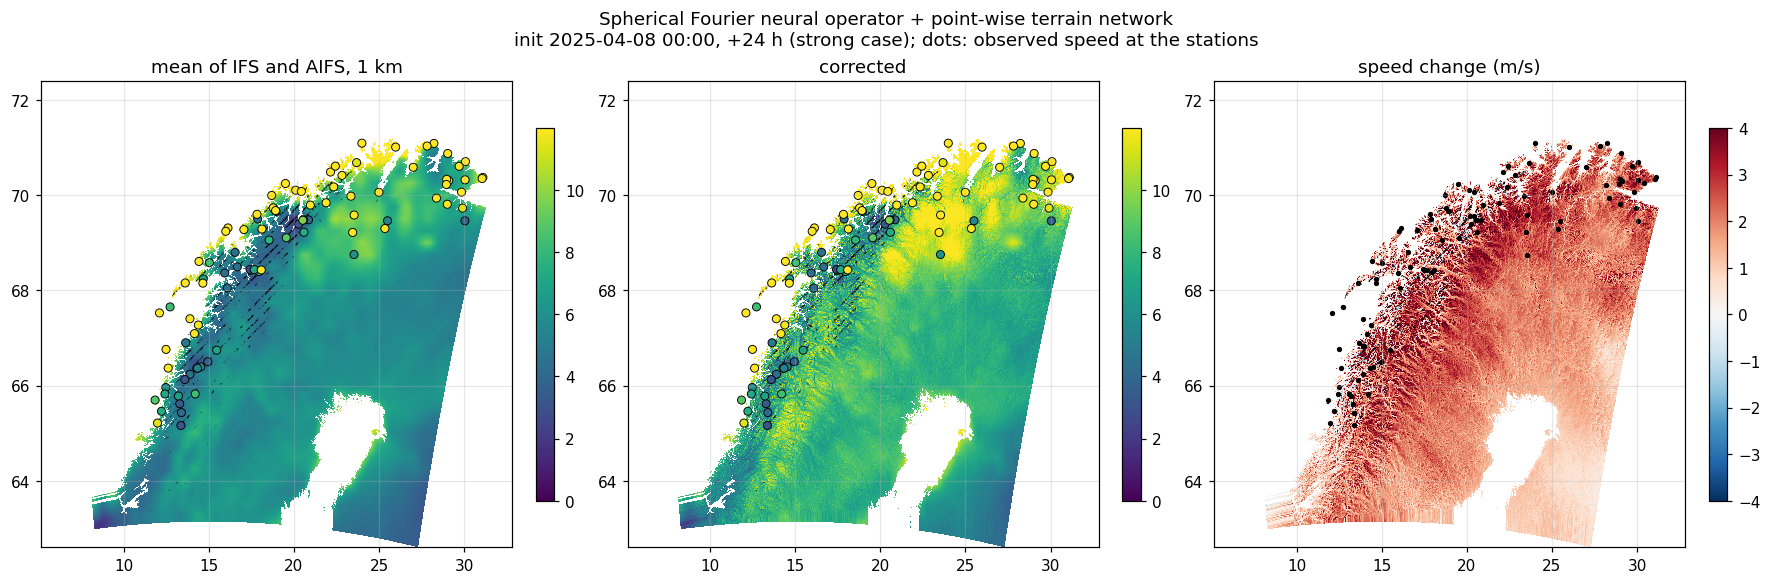

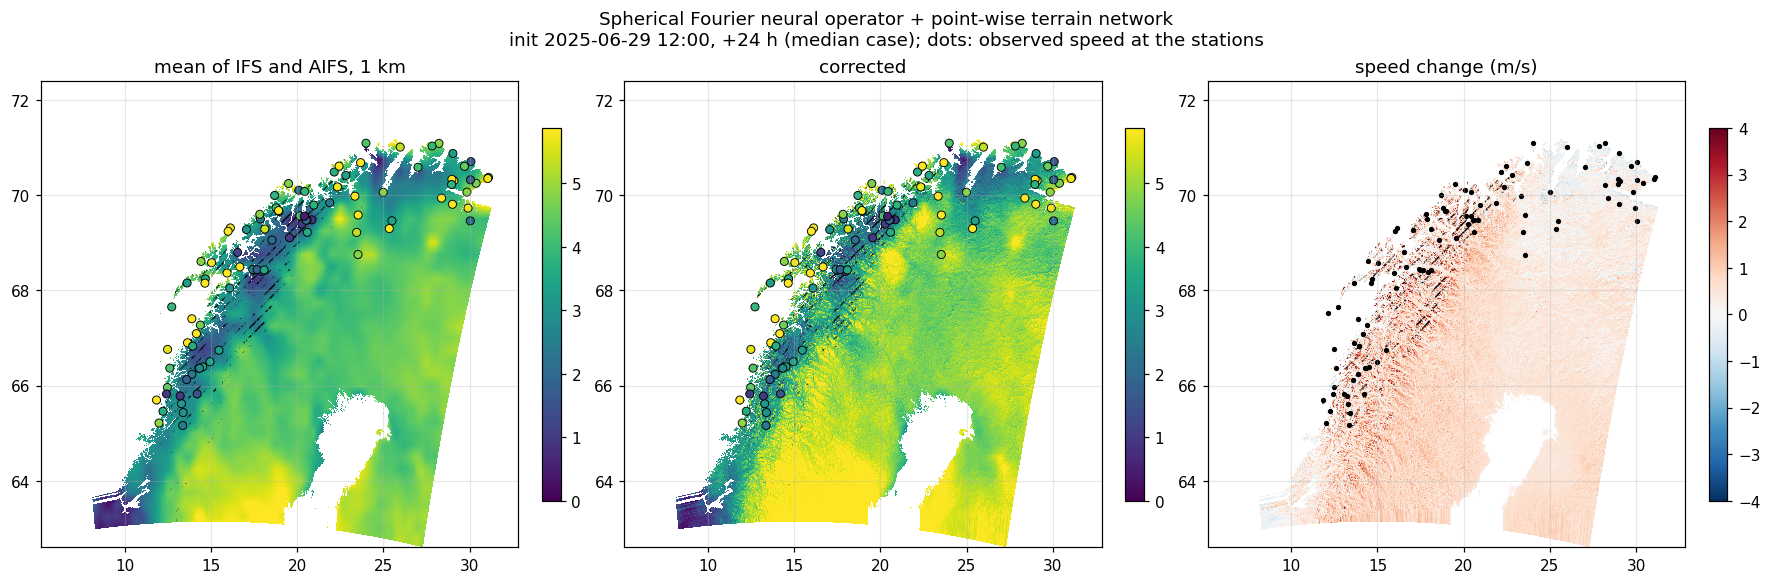

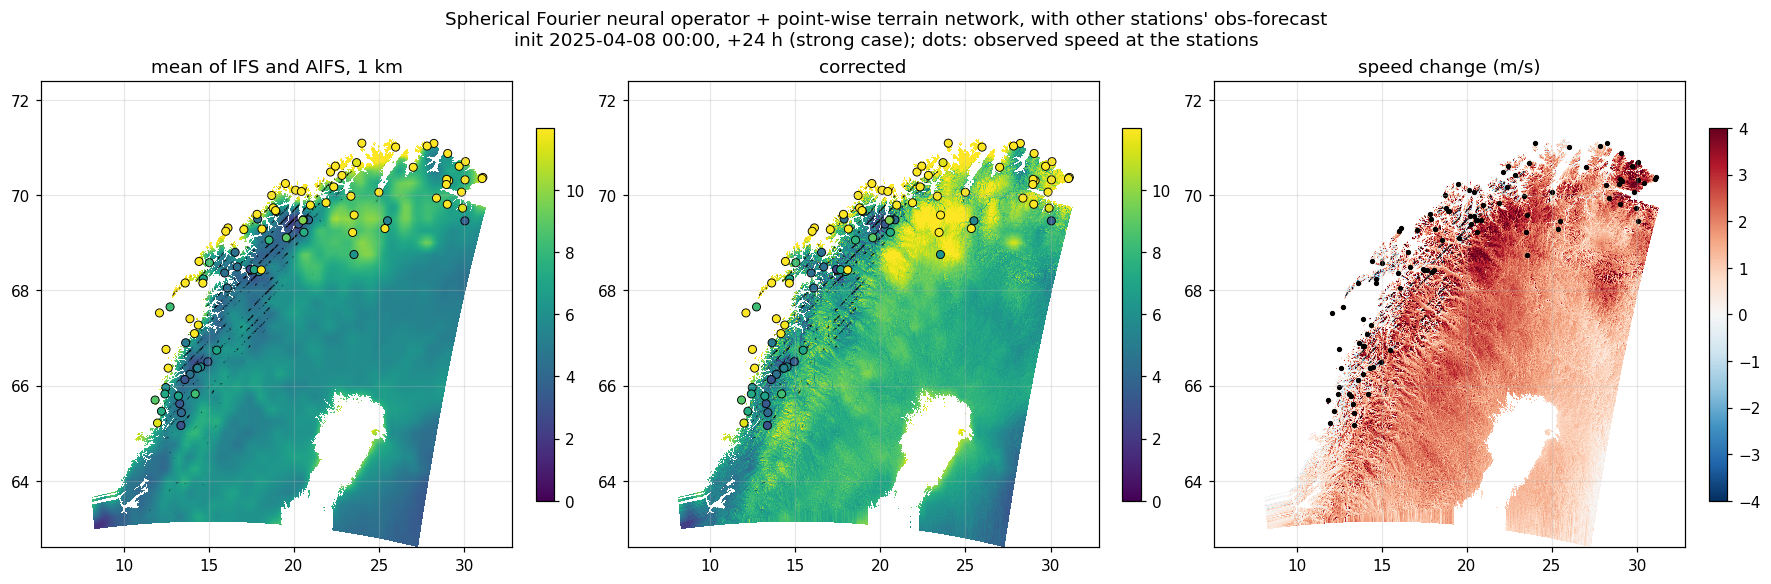

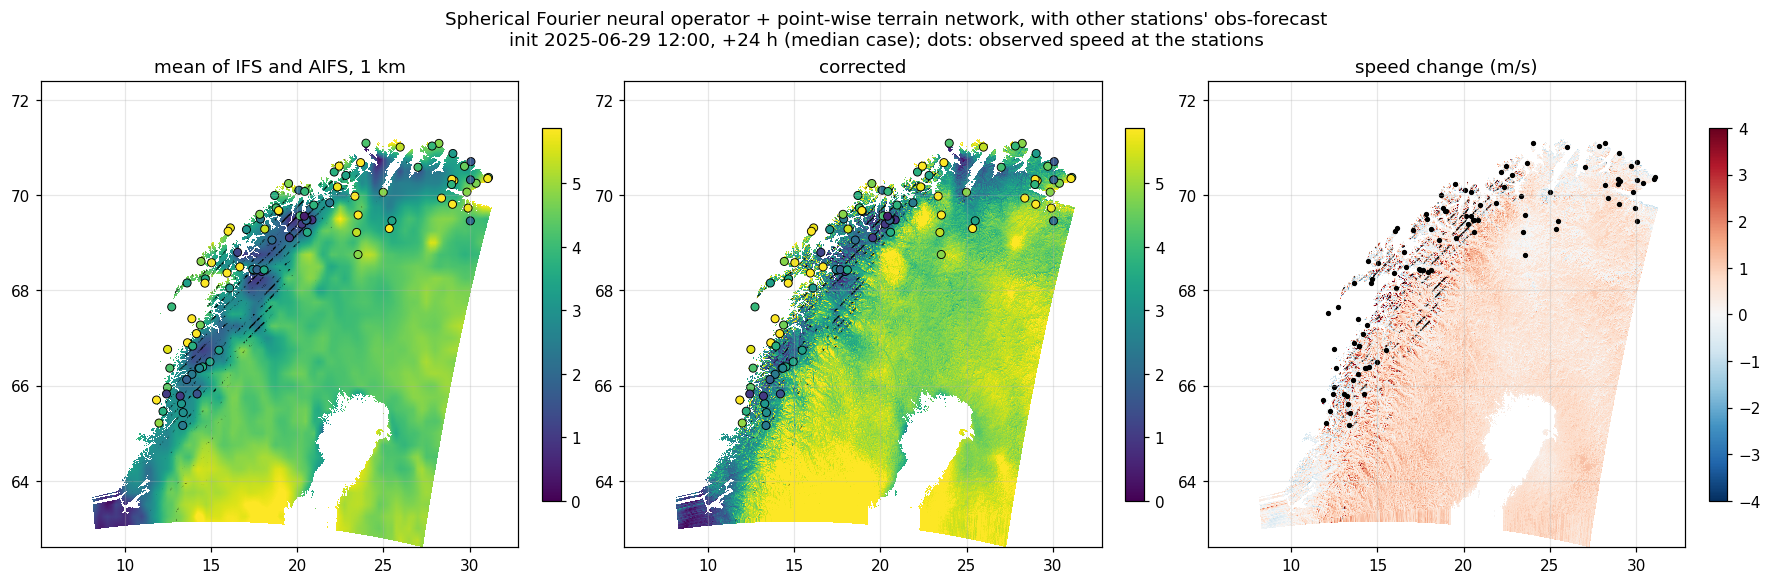

In [11]:
from matplotlib.colors import Normalize
for run, (nm_, G) in GRID.items():
    for case in ['strong', 'median']:
        b, c = G[f'{case}_base'], G[f'{case}_corr']
        sb, sc = np.linalg.norm(b, axis=-1), np.linalg.norm(b + c, axis=-1)
        sea = G['land'] < 0.5
        so = np.linalg.norm(G[f'{case}_obs'], axis=-1)
        vmax = np.nanpercentile(np.r_[sb[~sea].ravel(), so[np.isfinite(so)]], 99)
        fig, ax = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
        for a, f_, t_, cm, nrm in [(ax[0], sb, 'mean of IFS and AIFS, 1 km', 'viridis', Normalize(0, vmax)),
                                   (ax[1], sc, 'corrected', 'viridis', Normalize(0, vmax)),
                                   (ax[2], sc - sb, 'speed change (m/s)', 'RdBu_r', Normalize(-4, 4))]:
            f2 = np.where(sea, np.nan, f_)
            im = a.pcolormesh(G['lon'], G['lat'], f2, cmap=cm, norm=nrm, shading='auto', rasterized=True)
            a.contourf(G['lon'], G['lat'], np.where(sea, np.nan, (~inside).astype(float)), levels=[0.5, 1.5],
                       hatches=['////'], colors='none')
            a.set_facecolor('white')
            if a is not ax[2]:
                a.scatter(G['st_lon'], G['st_lat'], c=so, cmap=cm, norm=nrm, s=28, edgecolors='k', linewidths=.6)
            else:
                a.scatter(G['st_lon'], G['st_lat'], s=6, c='k')
            a.set_title(t_); plt.colorbar(im, ax=a, shrink=.8)
        fig.suptitle(f"{nm_}\ninit {str(G[f'{case}_init'])[:16]}, +24 h ({case} case); dots: observed speed at the stations")
        plt.show()

## 8. Findings

All numbers are vector RMSE change against the mean of IFS and AIFS, test period, on station
groups not used in training; negative = better.

1. **Six numbers per station hold almost the whole station-specific gain.**
   * One linear correction of the mean wind per station, A · (u, v) + b, gives −22.2 % at +6 h
     (A1 station-wise ridge regression: −22.8 %).
   * The speed factor varies a lot between stations (inter-quartile range 0.76–1.31).
2. **Terrain predicts part of these numbers.**
   * With ridge regression on the 28 descriptors, R² on held-out groups is 0.44 for A_uu,
     0.28 for A_vv, 0.23 for A_uv and 0.20 for b_u.
   * The predicted coefficients give −5.3 % at +6 h and −3.1 % at +66 h.
   * The same correction for all stations is worse than none (+1.0 %).
   * The Gaussian process with 28 length scales overfits the ~80 training stations.
3. **Terrain models on held-out stations** reach −4 to −5 % at short leads and −2 to −3.5 % at
   +66 h, whatever the model:

   | model | +6 h | +66 h |
   |---|---|---|
   | gradient boosting | −4.5 % | −3.2 % |
   | point-wise network | −4.2 % | −2.2 % |
   | Fourier neural operator + point-wise network | −4.2 % | −2.6 % |
   | spherical Fourier neural operator + point-wise network | −5.2 % | −3.3 % |

   * Without terrain every model is at or above zero.
   * In A1 the operators with coordinates gave about −1 %.
   * Roughly a quarter of the −22 % a station gets from its own history is recovered.
4. **Memorisation is the main trap; the limit is the number of stations.**
   * Ridge regression with terrain × wind is regularised per sample (about 600 000), not per
     station (about 80). It memorises training stations and is +1 to +2 % on held-out ones.
   * The weight sum of the inverse-distance weighting, nearly constant per station, let
     gradient boosting recognise stations: +5 to +7 %. It is no longer an input.
5. **The other stations' obs-forecast adds little on top of terrain.**
   * Spherical operator −5.5 % (vs −5.2 %) at +6 h, −3.6 % (vs −3.3 %) at +66 h.
   * Point-wise network −5.3 % (vs −4.2 %).
   * Gradient boosting −4.6 % (vs −4.5 %).
   * Without terrain it gives nothing (+0.6 %).
   * Training must take these inputs from other spatial groups only. With random hiding of
     25 % of stations, the held-out stations see farther neighbours than in training.
   * In A1 the Gaussian process with an elevation kernel got more from observations at the
     shortest leads (−6.6 % at +0 h).
6. **Which descriptors matter** (shuffled between stations):
   * shelter within 10 km: +4.3 %;
   * elevation and relative height: +2.9 %;
   * shelter within 1 km: +1.7 %;
   * land and coast: +0.3 %;
   * slope, aspect and roughness: ≈ 0.
7. **The 1 km product keeps the station skill.**
   * At withheld stations, the model wind at the station's cell plus the correction of the
     fold model that never saw it gives −5.2 % at +6 h and −3.3 % at +66 h, the same as the
     station-point predictions.
   * 96 % of land cells are within the descriptor range of the stations, but only 64 % above
     1100 m.
   * In the strongest case the correction raises the land-mean speed more with elevation:
     +1.0 m/s below 100 m, +4.6 m/s above 1100 m. Most stations are low and coastal, and none
     are in Sweden or Finland, so inland and mountain values are unverified extrapolation.

**Next.**
* Combine the terrain model with the Gaussian process with elevation for short leads (krige the
  terrain model's residual at init time).
* Add high and inland stations.
* Repeat with MEPS from 2024.

In [12]:
out = ROOT / 'results/a2'; out.mkdir(parents=True, exist_ok=True)
CHG.to_csv(out / 'rmse_change_pct.csv'); chg2.to_csv(out / 'rmse_change_pct_operators.csv')
r2.to_csv(out / 'coefficient_r2.csv'); imp.to_csv(out / 'importance.csv'); sdf.to_csv(out / 'per_station.csv', index=False)
print('written to', out)

written to /cluster/work/projects/nn8106k/siyan/windcast/results/a2
